# Atelier 3 : Apprentissage Supervisée 

## K-plus proche voisin (KNN) (Reconnaissance de chiffres)

### Question1

In [2]:
from sklearn.datasets import * 
import pandas as pd 
from sklearn.model_selection import train_test_split 
from sklearn.neighbors import KNeighborsClassifier 
digit = load_digits() 
dig = pd.DataFrame(digit['data'][0:1700]) 
print(dig.head()) 
print(digit.keys()) 

    0    1    2     3     4     5    6    7    8    9   ...   54   55   56  \
0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  0.0  ...  5.0  0.0  0.0   
3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  8.0  ...  9.0  0.0  0.0   
4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    57   58    59    60    61   62   63  
0  0.0  6.0  13.0  10.0   0.0  0.0  0.0  
1  0.0  0.0  11.0  16.0  10.0  0.0  0.0  
2  0.0  0.0   3.0  11.0  16.0  9.0  0.0  
3  0.0  7.0  13.0  13.0   9.0  0.0  0.0  
4  0.0  0.0   2.0  16.0   4.0  0.0  0.0  

[5 rows x 64 columns]
dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])


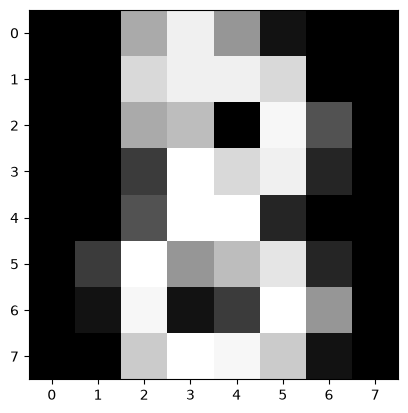

In [6]:
import matplotlib.pyplot as plt
plt.imshow(digit['images'][8], cmap='Greys_r') 
plt.show() 

In [7]:
train_x = digit.data # input variables 
train_y = digit.target # les étiquettes (output variable) 
#découpage du jeu de données (0.25 pour indiquer 25%) 
x_train,x_test,y_train,y_test=train_test_split(train_x,train_y,test_size=0.25)  

### Train 

In [27]:
KNN = KNeighborsClassifier(7) # on utilise 7 voisins 
KNN.fit(x_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](10,)","[0,1,2,...,7,8,9]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### Test 


In [28]:
print(KNN.score(x_test,y_test))

0.9933333333333333


### Validez le choix de K empiriquement.

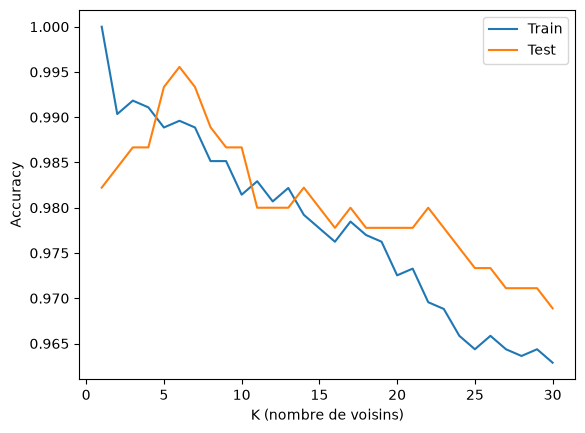

K maximisant le score test : 6


In [29]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

digit = load_digits()
train_x = digit.data      # variables d'entrée
train_y = digit.target    # étiquettes

x_train, x_test, y_train, y_test = train_test_split(
    train_x, train_y, test_size=0.25, random_state=42)

k_values = range(1, 31)
train_scores, test_scores = [], []

for k in k_values:
    knn = KNeighborsClassifier(k)
    knn.fit(x_train, y_train)
    train_scores.append(knn.score(x_train, y_train))
    test_scores.append(knn.score(x_test, y_test))

plt.plot(k_values, train_scores, label='Train')
plt.plot(k_values, test_scores, label='Test')
plt.xlabel('K (nombre de voisins)')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print("K maximisant le score test :", k_values[np.argmax(test_scores)])

### k-fold cross-validation, avec un K = 5

## Bayésien Naïf (SPAM Filter) 

## Question 2

In [40]:
import numpy as np 
import pandas as pd 
import os 
import matplotlib.pyplot as plt 
import seaborn as sns 
print(os.listdir("datasets")) 
df = pd.read_csv('datasets/spam.csv', encoding='latin-1')[['v1', 'v2']] 
df.columns = ['label', 'message'] 
print(df.head()) 

['diabetes.csv', 'MultivariateLinearRegression.xlsx', 'Position_Salaries.csv', 'spam.csv', 'univariateLinearRegression.csv']
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [42]:
import nltk 
nltk.download('stopwords') 
print(nltk.corpus.stopwords.words('english'))

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Administrateur\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [44]:
import string 
from nltk.corpus import stopwords #Natural Language Toolkit 
from nltk import PorterStemmer as Stemmer 
def process(text): 
    # lowercase it 
    text = text.lower() 
    # remove punctuation 
    text = ''.join([t for t in text if t not in string.punctuation]) 
    # remove stopwords 
    text = [t for t in text.split() if t not in 
stopwords.words('english')] 
    # stemming 
    st = Stemmer() 
    text = [st.stem(t) for t in text] 
    # return token list 
    return text 
# Testing 
print(process('It\'s holiday and we are playing cricket. Jeff is playing very well!!!')) 
# Test avec notre dataset 
print(df['message'][:20].apply(process))

['holiday', 'play', 'cricket', 'jeff', 'play', 'well']
0     [go, jurong, point, crazi, avail, bugi, n, gre...
1                          [ok, lar, joke, wif, u, oni]
2     [free, entri, 2, wkli, comp, win, fa, cup, fin...
3         [u, dun, say, earli, hor, u, c, alreadi, say]
4     [nah, dont, think, goe, usf, live, around, tho...
5     [freemsg, hey, darl, 3, week, word, back, id, ...
6     [even, brother, like, speak, treat, like, aid,...
7     [per, request, mell, mell, oru, minnaminungint...
8     [winner, valu, network, custom, select, receiv...
9     [mobil, 11, month, u, r, entitl, updat, latest...
10    [im, gonna, home, soon, dont, want, talk, stuf...
11    [six, chanc, win, cash, 100, 20000, pound, txt...
12    [urgent, 1, week, free, membership, å£100000, ...
13    [ive, search, right, word, thank, breather, pr...
14                                       [date, sunday]
15    [xxxmobilemovieclub, use, credit, click, wap, ...
16                                     [oh, kim, 

In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer 
tfidfv = TfidfVectorizer(analyzer=process) 
data = tfidfv.fit_transform(df['message']) 
mess = df.iloc[2]['message'] 
print(mess) 
print(tfidfv.transform([mess])) 
#visualiser 
j = tfidfv.transform([mess]).toarray()[0] 
print('index\tidf\ttfidf\tterm') 
for i in range(len(j)): 
       if j[i] != 0: 
           print(i, format(tfidfv.idf_[i], '.4f'), format(j[i], '.4f'), 
tfidfv.get_feature_names_out()[i],sep='\t') 


Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21 stored elements and shape (1, 8097)>
  Coords	Values
  (0, 72)	0.2330497030932461
  (0, 413)	0.09987750376879972
  (0, 420)	0.22518719340674634
  (0, 433)	0.22518719340674634
  (0, 833)	0.2190885570936267
  (0, 1180)	0.16669800498830506
  (0, 2076)	0.19516151371199045
  (0, 2246)	0.20302402339849024
  (0, 2748)	0.3571909758763146
  (0, 2868)	0.4660994061864922
  (0, 2969)	0.16669800498830506
  (0, 3091)	0.11505037200973967
  (0, 4592)	0.15903719770411495
  (0, 5768)	0.2330497030932461
  (0, 5815)	0.2330497030932461
  (0, 5856)	0.16027970945850903
  (0, 6959)	0.11759458460817876
  (0, 7099)	0.2190885570936267
  (0, 7276)	0.12336193745345178
  (0, 7708)	0.14471405235314777
  (0, 7741)	0.18906287739887084
index	idf	tfidf	term
72	8.5271	0.2330	08452810075over18
413	3.6544	

##### TRAIN 

In [49]:
from sklearn.pipeline import Pipeline 
from sklearn.naive_bayes import MultinomialNB 
from sklearn.model_selection import train_test_split 
spam_filter = Pipeline([ 
    ('vectorizer', TfidfVectorizer(analyzer=process)), # messages to weighted TFIDF score 
    ('classifier', MultinomialNB())   # train on TFIDF vectors with NB 
]) 
x_train, x_test, y_train, y_test = train_test_split(df['message'], 
df['label'], test_size=0.20, random_state = 21) 
spam_filter.fit(x_train, y_train) 

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vectorizer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U4](2,)","['ham','spam']"
,"analyzer analyzer: {'word', 'char', 'char_wb'} or callable, default='word'Whether the feature should be made of word or character n-grams.Option 'char_wb' creates character n-grams only from text insideword boundaries; n-grams at the edges of words are padded with space.If a callable is passed it is used to extract the sequence of featuresout of the raw, unprocessed input... versionchanged:: 0.21 Since v0.21, if ``input`` is ``'filename'`` or ``'file'``, the data is first read from the file and then passed to the given callable analyzer.",<function pro...0013F684349A0>
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


##### TEST  

In [50]:
predictions = spam_filter.predict(x_test) 
count = 0 
for i in range(len(y_test)): 
    if y_test.iloc[i] != predictions[i]: 
        count += 1 
print('Total number of test cases', len(y_test)) 
print('Number of wrong of predictions', count) 

Total number of test cases 1115
Number of wrong of predictions 39


#### Visualiser les prédictions erronées

In [52]:
# Récupérer les indices des prédictions erronées
errors = x_test[y_test != predictions]

# Afficher les messages et leurs classes
for i in errors.index:
    print("Message :", x_test.loc[i])
    print("Classe réelle :", y_test.loc[i])
    print("Classe prédite :", predictions[list(x_test.index).index(i)])
    print("-" * 50)

Message : Send a logo 2 ur lover - 2 names joined by a heart. Txt LOVE NAME1 NAME2 MOBNO eg LOVE ADAM EVE 07123456789 to 87077 Yahoo! POBox36504W45WQ TxtNO 4 no ads 150p
Classe réelle : spam
Classe prédite : ham
--------------------------------------------------
Message : sexy sexy cum and text me im wet and warm and ready for some porn! u up for some fun? THIS MSG IS FREE RECD MSGS 150P INC VAT 2 CANCEL TEXT STOP
Classe réelle : spam
Classe prédite : ham
--------------------------------------------------
Message : Twinks, bears, scallies, skins and jocks are calling now. Don't miss the weekend's fun. Call 08712466669 at 10p/min. 2 stop texts call 08712460324(nat rate)
Classe réelle : spam
Classe prédite : ham
--------------------------------------------------
Message : Hey Boys. Want hot XXX pics sent direct 2 ur phone? Txt PORN to 69855, 24Hrs free and then just 50p per day. To stop text STOPBCM SF WC1N3XX
Classe réelle : spam
Classe prédite : ham
------------------------------------

In [53]:
message = [
    "Your cash-balance is currently 500 pounds - to maximize your cash-in now, send COLLECT to 83600."
]

prediction = spam_filter.predict(message)

print("Classe prédite :", prediction[0])

Classe prédite : spam


In [54]:
#Calculez Rappel Précision F1 score 
from sklearn.metrics import classification_report 
print(classification_report(predictions, y_test)) 

              precision    recall  f1-score   support

         ham       1.00      0.96      0.98      1014
        spam       0.72      1.00      0.84       101

    accuracy                           0.97      1115
   macro avg       0.86      0.98      0.91      1115
weighted avg       0.97      0.97      0.97      1115



# Régression Linéaire (Prédiction du gain) 

## Question 3

In [56]:
import pandas as pd 
import matplotlib.pyplot as plt 
from scipy import stats 
df = pd.read_csv("datasets\\univariateLinearRegression.csv") 
print(len(df))

96


In [57]:
#selection de la première colonne de la base (la taille de la population) 
X = df.iloc[0:len(df),0] 
#selection de la deuxième colonne de la base (le profit effectué) 
Y = df.iloc[0:len(df),1] 

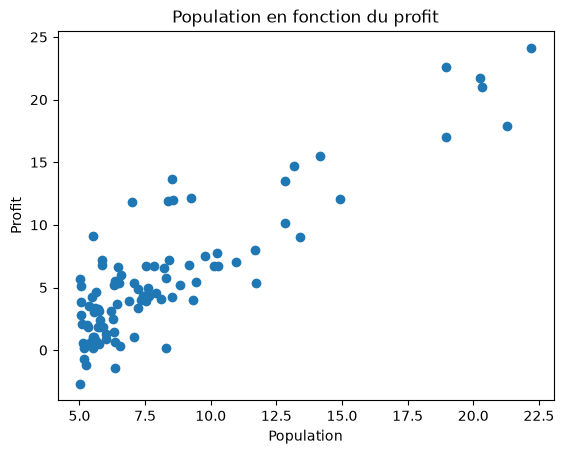

In [58]:
plt.scatter(X, Y)
plt.xlabel("Population")
plt.ylabel("Profit")
plt.title("Population en fonction du profit")
plt.show()

In [60]:
#linregress() renvoie plusieurs variables de retour. On s'interesse au slope et intercept 
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y) 

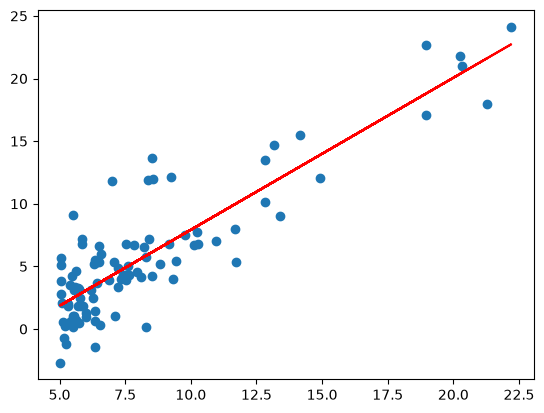

In [61]:
def F(x): 
    return slope * x + intercept 
#la variable fitLine est un tableau de valeurs prédites depuis la tableau de variables X 
fitLine = F(X) 
plt.scatter(X,Y) 
plt.plot(X, fitLine, c='r') 
plt.show() 

In [62]:
print (F(20.27)) 

20.38709883129833


# Régression multivariée (Prédiction du prix) 

## Question 4

In [67]:
import pandas as pd 
import statsmodels.api as sm 
from sklearn.preprocessing import StandardScaler 
import numpy as np 
from mpl_toolkits.mplot3d import Axes3D 
import matplotlib.pyplot as plt 
%pip install openpyxl

df = pd.read_excel(r"datasets\multivariateLinearRegression.xlsx")
print(df.head()) 


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
   taille_en_pieds_carre  nb_chambres    prix
0                   2104            3  399900
1                   1600            3  329900
2                   2400            3  369000
3                   1416            2  232000
4                   3000            4  539900


In [68]:
#Récupérer le prix : les valeurs observées pour la variable Cible 
Y = df["prix"] 
#Récupérer les variables prédictives : La superficie en pieds² et le nb chambre 
X = df[['taille_en_pieds_carre','nb_chambres']]

In [69]:
print(df.head())
print(X.shape)
print(Y.shape)

   taille_en_pieds_carre  nb_chambres    prix
0                   2104            3  399900
1                   1600            3  329900
2                   2400            3  369000
3                   1416            2  232000
4                   3000            4  539900
(47, 2)
(47,)


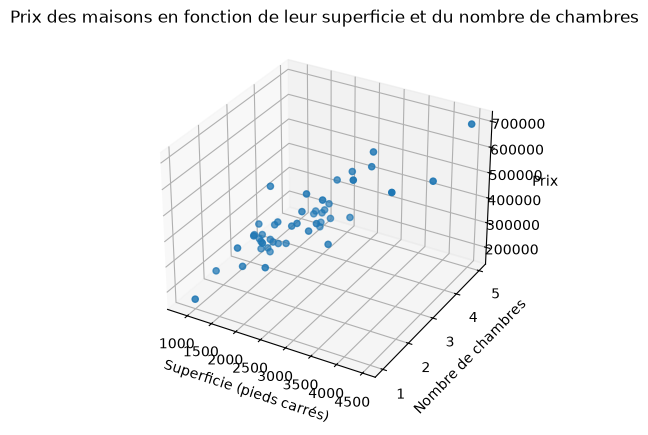

In [70]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    X['taille_en_pieds_carre'],
    X['nb_chambres'],
    Y
)

ax.set_xlabel('Superficie (pieds carrés)')
ax.set_ylabel('Nombre de chambres')
ax.set_zlabel('Prix')
ax.set_title('Prix des maisons en fonction de leur superficie et du nombre de chambres')

plt.show()

# Régression polynomiale (Prédiction du salaire) 

## Question 5

In [72]:
# Importez les libraries 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import PolynomialFeatures 
from sklearn.linear_model import LinearRegression 
df_sal = pd.read_csv('datasets/Position_Salaries.csv') 
df_sal.head() 

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [73]:
print(df_sal.head())
print(df_sal.describe())

            Position  Level  Salary
0   Business Analyst      1   45000
1  Junior Consultant      2   50000
2  Senior Consultant      3   60000
3            Manager      4   80000
4    Country Manager      5  110000
          Level          Salary
count  10.00000       10.000000
mean    5.50000   249500.000000
std     3.02765   299373.883668
min     1.00000    45000.000000
25%     3.25000    65000.000000
50%     5.50000   130000.000000
75%     7.75000   275000.000000
max    10.00000  1000000.000000


### Visualisation des données

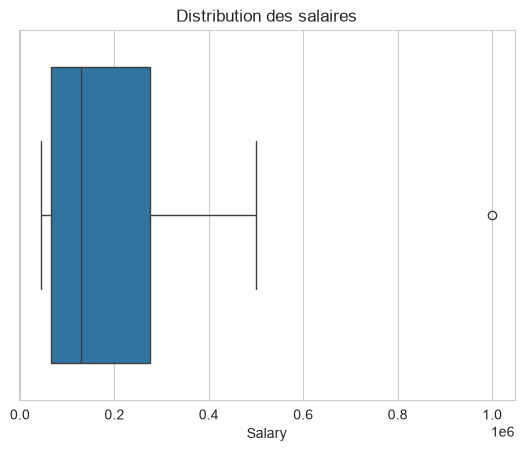

In [75]:
sns.set_style("whitegrid")

sns.boxplot(x=df_sal["Salary"])
plt.title("Distribution des salaires")
plt.show()

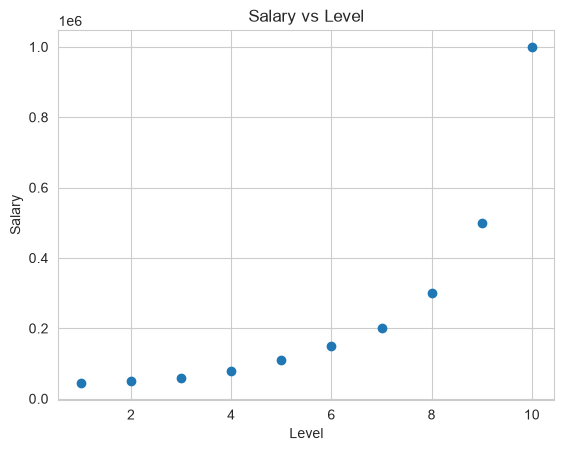

In [76]:
plt.scatter(X, y)
plt.title("Salary vs Level")
plt.xlabel("Level")
plt.ylabel("Salary")
plt.show()

## Question 6

In [78]:
X = df_sal.iloc[:, 1:-1].values  # independent 
y = df_sal.iloc[:, -1].values  # dependent 
 
# Train linear regression model  
lr = LinearRegression() 
lr.fit(X, y) 
 
# Train polynomial regression model  
pr = PolynomialFeatures(degree = 4) 
X_poly = pr.fit_transform(X) 
lr_2 = LinearRegression() 
lr_2.fit(X_poly, y) 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 0. ,-211002.33, 94765.44, -15463.29, 890.15]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.842e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](5,)","[10228.05, 126.69, 4.53, 0.25, 0. ]"


In [79]:
# TEST 
y_pred_lr = lr.predict(X)           # Linear Regression 
y_pred_poly = lr_2.predict(X_poly)  # Polynomial Regression 

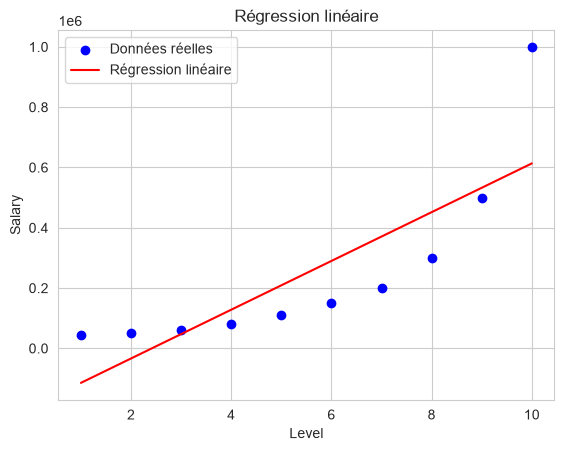

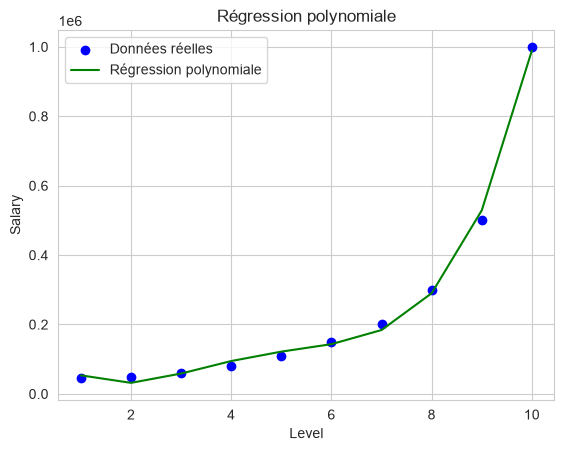

In [80]:
# Graphique de la régression linéaire
plt.scatter(X, y, color='blue', label='Données réelles')
plt.plot(X, y_pred_lr, color='red', label='Régression linéaire')

plt.title('Régression linéaire')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.legend()
plt.show()


# Graphique de la régression polynomiale
plt.scatter(X, y, color='blue', label='Données réelles')
plt.plot(X, y_pred_poly, color='green', label='Régression polynomiale')

plt.title('Régression polynomiale')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.legend()
plt.show()

In [81]:
# Prédiction avec la régression linéaire
print(f'Linear Regression result : {lr.predict([[7.5]])}')

# Prédiction avec la régression polynomiale
print(f'Polynomial Regression result :')
print(lr_2.predict(pr.fit_transform([[7.5]])))

Linear Regression result : [411257.57575758]
Polynomial Regression result :
[225126.29297787]
